In [114]:
import numpy as np
import os, glob, json
import pickle

import sys

# this is the path to the discovery folder
sys.path.insert(0, "./")
import discovery_new as ds

import matplotlib.pyplot as plt
import scipy
import jax.numpy as jnp

from scipy.stats import uniform
import jax

import copy

In [115]:
psr.backend_flags

array(['JBO.ROACH.1520', 'JBO.ROACH.1520', 'JBO.ROACH.1520', ...,
       'DE609.150', 'DE609.150', 'DE609.150'], shape=(6777,), dtype=object)

In [116]:
# this are the data we want to replicate
path = './dati/DR2low_feathers/'
s_dsfiles = np.sort(os.listdir(path))
psr = [ds.pulsar.Pulsar.read_feather(path + f'{psrfile}') for psrfile in s_dsfiles][9]

In [117]:
###### Let's put in the model the components we want to simulate (comment a line if you don't want to inject that process)

# data
model = [psr.residuals]
# timing model
model += [ds.makegp_timing(psr, svd=True, variance=1e-40)]
# white noise parameters
model += [ds.makenoise_measurement(psr, psr.noisedict, tnequad = True, ecorr=True)]
# red noise paramters
#model.append(ds.makegp_fourier(psr, ds.powerlaw, psr.noisedict[psr.name + '_red_components'], T=ds.getspan(psr), name='red_noise' ))
# DM variation parameters
#model.append(ds.makegp_fourier(psr, ds.powerlaw, psr.noisedict[psr.name + '_dm_components'], T=ds.getspan(psr), name='dm_gp', fourierbasis=ds.make_dmfourierbasis(alpha = 2.0, tndm = False)))
# scattering noise parameters
#model.append(ds.makegp_fourier(psr, ds.powerlaw, psr.noisedict[psr.name + '_chrom_components'], T=ds.getspan(psr), name='sv_gp', fourierbasis=ds.make_dmfourierbasis(alpha = 4.0, tndm = False)))

In [118]:

model.append(ds.makegp_fourier_select(psr, ds.powerlaw, 40, T=ds.getspan(psr), name='band_noise', selection=ds.lofar_backends))


In [119]:
gml = ds.PulsarLikelihood(model)
logL = ds.PulsarLikelihood(model).logL

In [120]:
logL.params

['J1640+2224_band_noise_gamma', 'J1640+2224_band_noise_log10_A']

In [121]:
truths = {
    'J1640+2224_band_noise_gamma': 3.,
    'J1640+2224_band_noise_log10_A': -14,  #-15, -14.5, -14.
}

In [122]:
# sample from the likelihood! jax.random.key(42) is the seed of the random extraction, you can change it to have a different realisation od the data simulated
_, residuals = gml.sample(jax.random.key(1), truths)

In [123]:
# make a copy of the pulsar object and overwite the residuals with the simulated ones
sim_psr = copy.deepcopy(psr)
sim_psr.residuals = np.array(residuals)

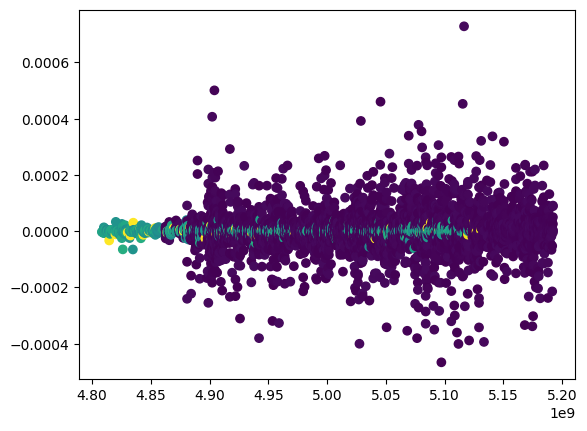

In [124]:
plt.scatter(sim_psr.toas, sim_psr.residuals, c=sim_psr.freqs)

injection band noise 3 volte e niente band nel modello 
poi inserisci anche nel modello 

In [ ]:
fit dei dati con alfa libero 